In [43]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch    
import torch.nn as nn
import torchvision
from torchvision import transforms

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from scipy.sparse import hstack, csr_matrix

In [44]:
np.random.seed(42)
torch.manual_seed(42)

DATA = 'data/train.csv'
IMAGES = 'data/train/train/'

dataset = pd.read_csv(DATA)

In [45]:
def verify_image_f(img_id):
    path = os.path.join(IMAGES, f"{img_id}.jpg")
    return os.path.isfile(path)

dataset['image_exist'] = dataset['ImgId'].apply(verify_image_f)
valid_image_count = dataset['image_exist'].sum()

print(f"ye: {valid_image_count} з {len(dataset)}")

ye: 7711 з 46229


In [46]:
dataset = dataset[dataset['image_exist']].reset_index(drop=True)

In [47]:
dataset['title'] = dataset['title'].fillna('')
dataset['description'] = dataset['description'].fillna('')
dataset['full_text'] = dataset['title'] + ' ' + dataset['description']

In [48]:
dataset['word_count'] = dataset['full_text'].apply(lambda x: len(str(x).split()))

print("\ndimension after filtr:", dataset.shape)
print("count dublovanih texts:", dataset['full_text'].duplicated().sum())
print("\nstatistics po count words in text:")
print(dataset['word_count'].describe())


dimension after filtr: (7711, 7)
count dublovanih texts: 8

statistics po count words in text:
count    7711.000000
mean      103.667099
std        99.065166
min         1.000000
25%        39.000000
50%        77.000000
75%       132.000000
max      1125.000000
Name: word_count, dtype: float64


In [49]:
category_counts = dataset['categories'].value_counts()
print("\rospodil object po categories:\n", category_counts)

ospodil object po categories:
 categories
Tools & Home Improvement     2000
Toys & Games                 2000
Electronics                  1724
Office Products               934
Cell Phones & Accessories     616
Patio, Lawn & Garden          350
Beauty                         87
Name: count, dtype: int64


C:\Users\user\AppData\Local\Temp\ipykernel_21820\418195139.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


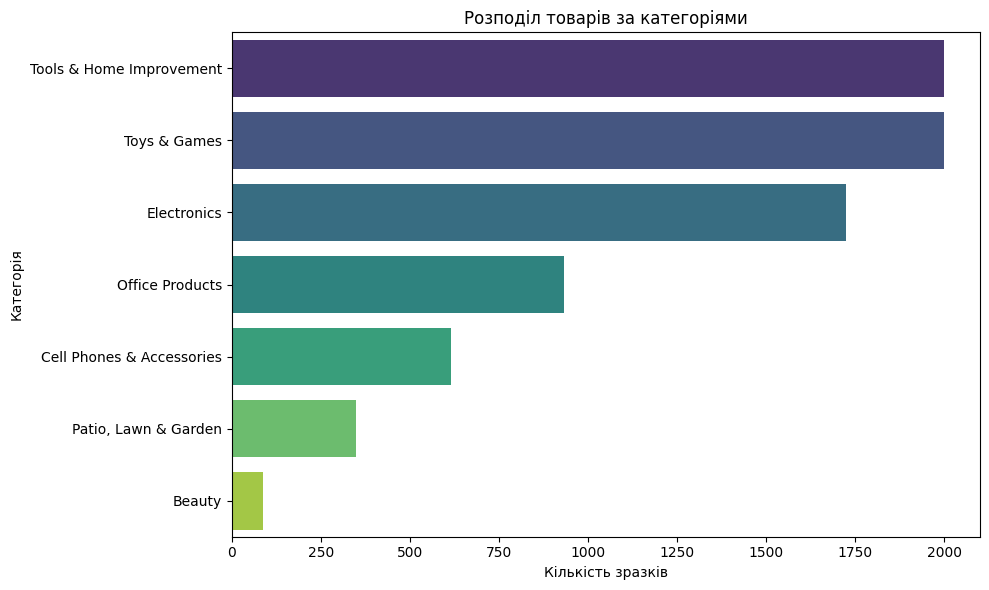

In [50]:
plt.figure(figsize=(10, 6))
sns.barplot(
    x=category_counts.values, 
    y=category_counts.index, 
    palette='viridis'
)
plt.title("Розподіл товарів за категоріями")
plt.xlabel("Кількість зразків")
plt.ylabel("Категорія")
plt.tight_layout()
plt.show()

In [51]:
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(dataset['categories'])
tfidf = TfidfVectorizer(max_features=10000, stop_words='english')
X_text = tfidf.fit_transform(dataset['full_text'])

In [52]:
X_train, X_test, y_train, y_test = train_test_split(X_text, y, test_size=0.2, random_state=42, stratify=y)

In [53]:
clf = LogisticRegression(max_iter=1000, C=1.0)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)

In [54]:
print("\nresult clasification")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, average='weighted'):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, average='weighted'):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred, average='weighted'):.4f}")


result clasification
Accuracy:  0.9443
Precision: 0.9451
Recall:    0.9443
F1-Score:  0.9427


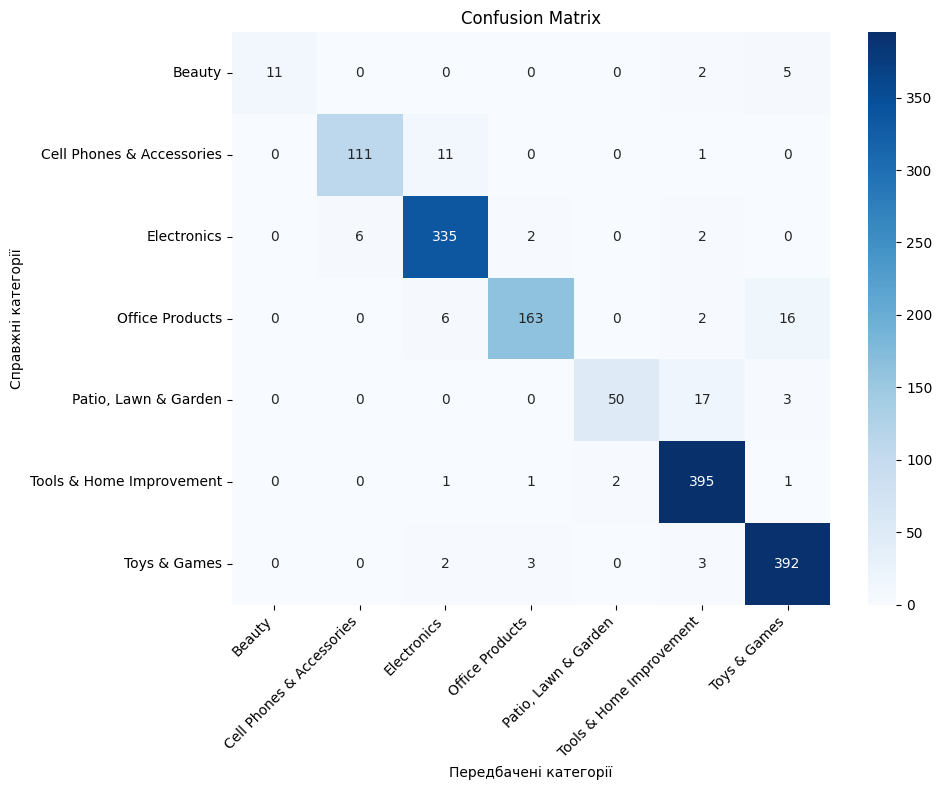

In [55]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    xticklabels=label_encoder.classes_, 
    yticklabels=label_encoder.classes_
)
plt.title('Confusion Matrix')
plt.xlabel('Передбачені категорії')
plt.ylabel('Справжні категорії')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()